In [43]:
from kernelprob.configs.config import *
import matplotlib.pyplot as plt
import numpy as np
import scienceplots
import numpy as np
plt.style.use('science')

# Load in files into a giant dictionary
# filename format: dataset_estimator_weighting

dataset_names = DATASETS['small_n'] + DATASETS['big_n']
dataset_lookup = {
    'California' : 8,
    'Adult' : 12,
    'Independent' : 60,
    'Correlated' : 60,
    'NHANES' : 79,
    'Communities' : 101,
}

all_weights = [
    'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16',
    'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16',
    'weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9',
    'beta_shapley_1_1', 
    'banzhaf', # Important to include this last
    'shapley' # Important to include this last
]

weight_lookup = {
    'beta_shapley_1_1' : 'B(1,1)',
    'beta_shapley_2_2' : 'B(2,2)',
    'beta_shapley_4_4' : 'B(4,4)',
    'beta_shapley_8_8' : 'B(8,8)',
    'beta_shapley_16_16' : 'B(16,16)',
    'beta_shapley_1_2' : 'B(1,2)',
    'beta_shapley_1_4' : 'B(1,4)',
    'beta_shapley_1_8' : 'B(1,8)',
    'beta_shapley_1_16' : 'B(1,16)',
    'weighted_banzhaf_0.5' : 'WB(0.5)',
    'weighted_banzhaf_0.6' : 'WB(0.6)',
    'weighted_banzhaf_0.7' : 'WB(0.7)',
    'weighted_banzhaf_0.8' : 'WB(0.8)',
    'weighted_banzhaf_0.9' : 'WB(0.9)',
    'banzhaf' : 'Banzhaf',
    'shapley' : 'Shapley',
}

weightings = {
    'Symmetric Beta' :
        ['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16'],
    'Asymmetric Beta' : 
        ['beta_shapley_1_1', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16'],
    'Weighted Banzhaf' : 
        ['weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']
}



# General estimators in ESTIMATOR_ALL
# Shapley estiamtors in ESTIMATOR_SHAPLEY
# Banzhaf estimators in ESTIMATOR_BANZHAF

# Load in all the files into a dictionary called results


# Get list of files in outputs folder
import os


def extract_helper(filename, valid_names):
    for name in valid_names:
        if name in filename:
            return name
    raise ValueError(f'Could not find valid name in filename {filename}')

def load_filtered_error(filter, extra_variable = None):
    results = {}
    filenames = os.listdir('output')
    for filename in filenames:
        if filename == '.DS_Store': continue
        # The challenge is that there are extra underscores in the filename that we need to account for
        dataset = extract_helper(filename, dataset_names)
        estimator = extract_helper(filename, ESTIMATOR_FACTORY.keys())
        weighting = extract_helper(filename, all_weights)

        # Load in the file
        with open(f'output/{filename}', 'r') as f:
            # Each line is a dictionary, we want to e
            for line in f:
                if 'inf' in line or 'nan' in line: continue
                line = eval(line)
                # Check if the line is valid
                if 'sample_size' in filter:
                    if line['sample_size'] // line['n'] not in filter['sample_size']:
                        continue
                if 'noise' in filter:
                    if line['noise'] not in filter['noise']:
                        continue
                # Add to the results
                if dataset not in results:
                    results[dataset] = {}
                if weighting not in results[dataset]:
                    results[dataset][weighting] = {}
                if estimator not in results[dataset][weighting]:
                    if extra_variable is None:
                        results[dataset][weighting][estimator] = []
                    else:
                        results[dataset][weighting][estimator] = {}
                if extra_variable is None:
                    results[dataset][weighting][estimator].append(line['error'])
                else:
                    if line[extra_variable] not in results[dataset][weighting][estimator]:
                        results[dataset][weighting][estimator][line[extra_variable]] = []  
                    results[dataset][weighting][estimator][line[extra_variable]].append(line['error'])
                    
    return results

def load_fit_error(dataset, ground_truth_class):
    filename = f'output/fit_{dataset}.csv'
    errors = {
        'Linear' : {}, 'RandomForest' : {}, 'XGBoost' : {}
    }
    with open(filename, 'r') as f:
        for line in f:
            dict = eval(line)
            if dict['ground_truth_class'] != ground_truth_class:
                continue
            sm, rm = dict['sample_multiplier'], dict['reg_model_class']
            if sm not in errors[rm]:
                errors[rm][sm] = []
            errors[rm][sm].append(dict['error'])
    return errors

In [44]:
cb_colors = [
    "#D55E00",  # Vermillion
    "#56B4E9",  # Sky Blue
    "#44AA99",  # Teal
    "#AA4499",  # Magenta
    "#009E73",  # Bluish Green
    "#0072B2",  # Blue
    "#E69F00",  # Orange
    "#CC79A7",  # Reddish Purple
    "#F0E442",  # Yellow
    "#999999",  # Gray
    "#882255",  # Dark Red-Purple
    "#117733",  # Forest Green
    "#88CCEE",  # Light Cyan
    "#CC6677",  # Coral Pink
    "#332288",  # Dark Navy
]

linestyles = [
    '-',               # Solid Line
    '--',              # Dashed Line
    '-.',              # Dash-Dot Line
    (0, (1, 1)),       # Dense Dots
    ':',               # Dotted Line
    (0, (1, 10)),      # Dash-Dot with large gaps
    (0, (5, 10)),      # Long Dashes
    (0, (3, 1, 1, 1)), # Dense Dash-Dot
    (0, (3, 5, 1, 5)), # Dash-Dot with medium gaps
    (0, (10, 1)),      # Very Long Dashes
    (0, (5, 2, 1, 2)), # Custom Dense Pattern
    (0, (7, 3)),       # Long Dash with Gaps
    (0, (2, 2, 10, 2)),# Double Dash with Gap
    (0, (4, 4, 1, 4)), # Dash-Dot-Dot
    (0, (6, 2, 1, 2)), # Custom Alternating
]

In [45]:
# Make a giant plot
# The columns are the datasets
# The rows are the weightings i.e., beta_shapley_sym, beta_shapley_asym, weighted_banzhaf
# Each subplot is a line plot of the error for each estimator

filter = {
    'sample_size' : [10],
    'noise' : [0]
}
results = load_filtered_error(filter)

filenames = [
    'images/prob_regadj.pdf',
    'images/prob_leverageshap+.pdf',
    'images/prob_kernelbanzhaf+.pdf',
]
use_estimators = [
    'RegressionAdjusted',
    'MonteCarlo', 
    'KernelBanzhaf+',
    'LeverageSHAP+',
    'WSL',
    'OFA_S'
]
include_by_filename = {
    'images/prob_regadj.pdf' : ['RegressionAdjusted', 'MonteCarlo', 'KernelBanzhaf+', 'LeverageSHAP+', 'WSL', 'OFA_S'],
    'images/prob_leverageshap+.pdf' : ['MonteCarlo', 'LeverageSHAP+'],
    'images/prob_kernelbanzhaf+.pdf' : ['MonteCarlo', 'KernelBanzhaf+'],
}

for filename in filenames:
    fig, axs = plt.subplots(len(weightings), len(dataset_names), figsize=(11, 5.5))

    all_handles = {}
    for i, (weight_list_name, weight_list) in enumerate(weightings.items()):
        print(weight_list)
        for j, dataset in enumerate(dataset_names):
            if i == 0:
                axs[i, j].set_title(fr'{dataset} ($n={dataset_lookup[dataset]}$)')
            if j == 0:
                axs[i, j].set_ylabel(fr'$\ell_2$-error')
                axs[i,j].annotate(weight_list_name,
                    xy=(-.75, 0.5),              # Coordinates in axis fraction
                    xycoords='axes fraction', # Relative to the axis
                    fontsize=12,
                    rotation=90,              # Rotate to align with y-axis
                    ha='center',              # Centered horizontally
                    va='center',              # Centered vertically
                    color='black')
            for estimator_idx, estimator in enumerate(use_estimators):
                if weight_list[-2] not in results[dataset]:
                    continue
                if estimator not in results[dataset][weight_list[-2]]:
                    continue
                if estimator not in include_by_filename[filename]:
                    continue
                errors = [np.mean(results[dataset][weighting][estimator]) for weighting in weight_list]
                prettier_weight_list = [weight_lookup[weighting] for weighting in weight_list]
            
                # Rotate the x-axis labels
                axs[i, j].set_xticks(np.arange(len(prettier_weight_list)))
                axs[i, j].set_xticklabels(prettier_weight_list, rotation=30)
                line, = axs[i, j].plot(prettier_weight_list, errors, 
                                    label=estimator, 
                                    linestyle=linestyles[estimator_idx], 
                                    color=cb_colors[estimator_idx], linewidth=2)

                # Add the line handle to the global collection
                if estimator not in all_handles:
                    all_handles[estimator] = line
            axs[i, j].set_yscale('log')

    fig.suptitle('Probabilistic Value Estimator Error', fontsize=16)
    # Two layers of legends
    fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=len(all_handles), bbox_to_anchor=(0.45,0), fontsize=11)
    
    plt.tight_layout()
    
    plt.savefig(filename, bbox_inches='tight', dpi=300)
    plt.show()


ValueError: Could not find valid name in filename fit_California.csv

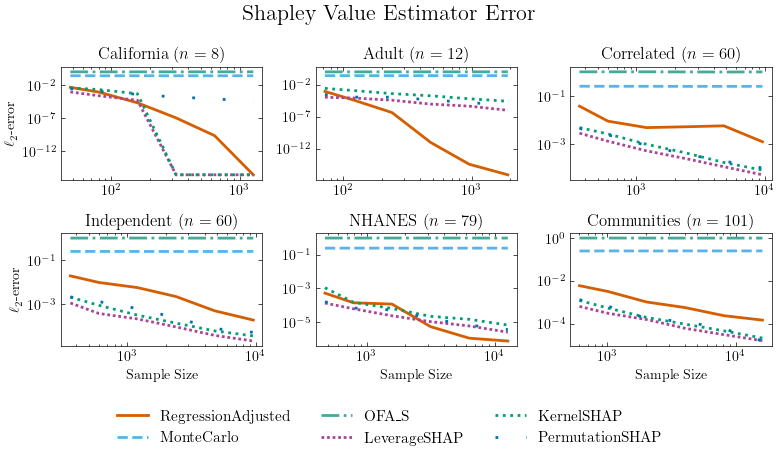

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define datasets and parameters
extra_variable = 'sample_size'
extra_variable_vals = np.array([6, 10, 20, 40, 80, 160])
filter = {'sample_size': extra_variable_vals, 'noise': [0]}

# Load filtered error results
results = load_filtered_error(filter, extra_variable=extra_variable)

datasets = results.keys()  # Assuming results contain dataset keys
fig, axs = plt.subplots(2, len(datasets)//2, figsize=(8, 4))
all_handles = {}

use_estimators = [
    'RegressionAdjusted',
    'MonteCarlo',
    'OFA_S',
    'LeverageSHAP',
    'KernelSHAP',
    'PermutationSHAP',
]

# Iterate through datasets
# Sort the datasets by the number of samples
datasets = sorted(datasets, key=lambda x: dataset_lookup[x])
for j, dataset in enumerate(datasets):
    if 'shapley' not in results[dataset]:
        continue
    row = j // (len(datasets)//2)
    col = j % (len(datasets)//2)
    ax = axs[row, col]
    
    for estimator_idx, estimator in enumerate(use_estimators):

        if estimator not in results[dataset]['shapley']:
            continue
        
        errors = []
        for val in extra_variable_vals:
            adjusted_val = int(dataset_lookup[dataset] * val)
            errors.append(np.mean(results[dataset]['shapley'][estimator][adjusted_val]))

        line, = ax.plot(extra_variable_vals * dataset_lookup[dataset], errors,
                            label=estimator,
                            linestyle=linestyles[estimator_idx],
                            color=cb_colors[estimator_idx], linewidth=2)
        
        if estimator not in all_handles:
            all_handles[estimator] = line
    
    if col == 0:
        ax.set_ylabel(r'$\ell_2$-error')
    if row == 1:
        ax.set_xlabel('Sample Size')
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.set_title(f'{dataset} ($n={dataset_lookup[dataset]}$)')

# Overall figure title and legend
fig.suptitle('Shapley Value Estimator Error', fontsize=16)
fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', 
           ncol=len(all_handles)//2, bbox_to_anchor=(0.5, 0), fontsize=11)
plt.tight_layout()
plt.savefig('images/prob_shapley_sample_size.pdf', bbox_inches='tight', dpi=300)
plt.show()


['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16']
Dataset: Communities, Weight: shapley, Estimator: KernelBanzhaf+, Val: 606
No data for dataset: Communities, Weight: shapley, Estimator: KernelBanzhaf+
Dataset: Communities, Weight: shapley, Estimator: OFA_S, Val: 606
Dataset: Communities, Weight: shapley, Estimator: OFA_S, Val: 1010
Dataset: Communities, Weight: shapley, Estimator: OFA_S, Val: 2020
Dataset: Communities, Weight: shapley, Estimator: OFA_S, Val: 4040
Dataset: Communities, Weight: shapley, Estimator: OFA_S, Val: 8080
Dataset: Communities, Weight: shapley, Estimator: OFA_S, Val: 16160
Dataset: Communities, Weight: shapley, Estimator: RegressionAdjusted, Val: 606
Dataset: Communities, Weight: shapley, Estimator: RegressionAdjusted, Val: 1010
Dataset: Communities, Weight: shapley, Estimator: RegressionAdjusted, Val: 2020
Dataset: Communities, Weight: shapley, Estimator: RegressionAdjusted, Val: 4040
Dataset: Communities, We

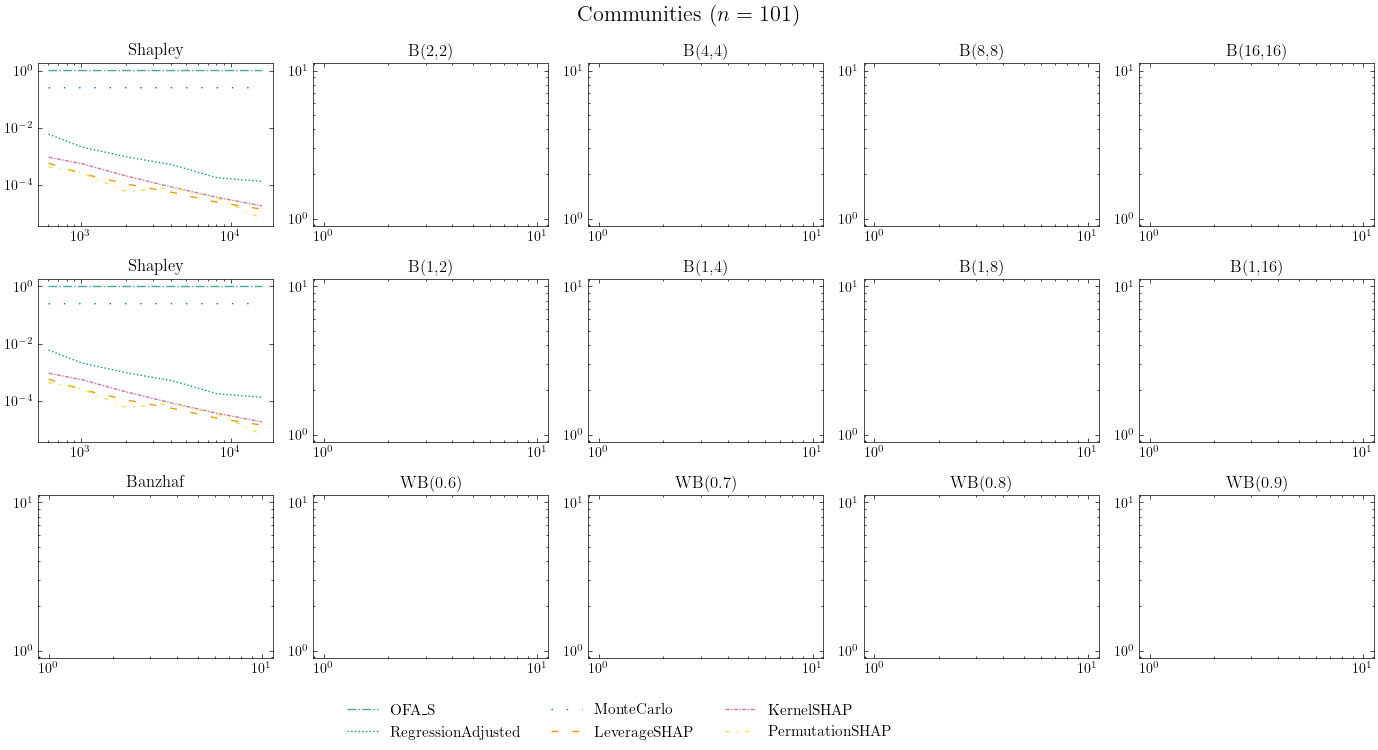

In [ ]:
# Make a giant plot
# The columns are the datasets
# The rows are the weightings i.e., beta_shapley_sym, beta_shapley_asym, weighted_banzhaf
# Each subplot is a line plot of the error for each estimator and the x axis is the number of samples on one of the weightings in the class of the row

fig, axs = plt.subplots(len(weightings), 5, figsize=(14, 7))


extra_variable = 'sample_size'
extra_variable_vals = np.array([6, 10, 20, 40, 80, 160])

filter = {
    'sample_size' : extra_variable_vals,
    'noise' : [0],
}

results = load_filtered_error(filter, extra_variable=extra_variable)

all_handles = {}
for i, (weight_list_name, weight_list) in enumerate(weightings.items()):
    print(weight_list)
    for j, weight in enumerate(weight_list):
        if weight == 'beta_shapley_1_1':
            weight = 'shapley'
        if weight == 'weighted_banzhaf_0.5':
            weight = 'banzhaf'
        for estimator_idx, estimator in enumerate(ESTIMATOR_FACTORY.keys()):
            if weight not in results[dataset]: continue
            if estimator not in results[dataset][weight]: continue
            errors = []
            try:
                for val in extra_variable_vals:
                    if extra_variable == 'sample_size':
                        val = int(dataset_lookup[dataset]*val)
                    print(f'Dataset: {dataset}, Weight: {weight}, Estimator: {estimator}, Val: {val}')
                    errors.append(np.median(results[dataset][weight][estimator][val]))
            except:
                print(f'No data for dataset: {dataset}, Weight: {weight}, Estimator: {estimator}')
                continue

            line, = axs[i, j].plot(extra_variable_vals*dataset_lookup[dataset], errors, 
                                   label=estimator, 
                                   linestyle=linestyles[estimator_idx], 
                                   color=cb_colors[estimator_idx])

            # Add the line handle to the global collection
            if estimator not in all_handles:
                all_handles[estimator] = line
        axs[i, j].set_yscale('log')
        axs[i, j].set_xscale('log')
        axs[i, j].set_title(weight_lookup[weight])

fig.suptitle(f'{dataset} ($n={dataset_lookup[dataset]}$)', fontsize=16)
# Two layers of legends
fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=len(all_handles)//2, bbox_to_anchor=(0.45,0), fontsize=11)
plt.tight_layout()
plt.show()

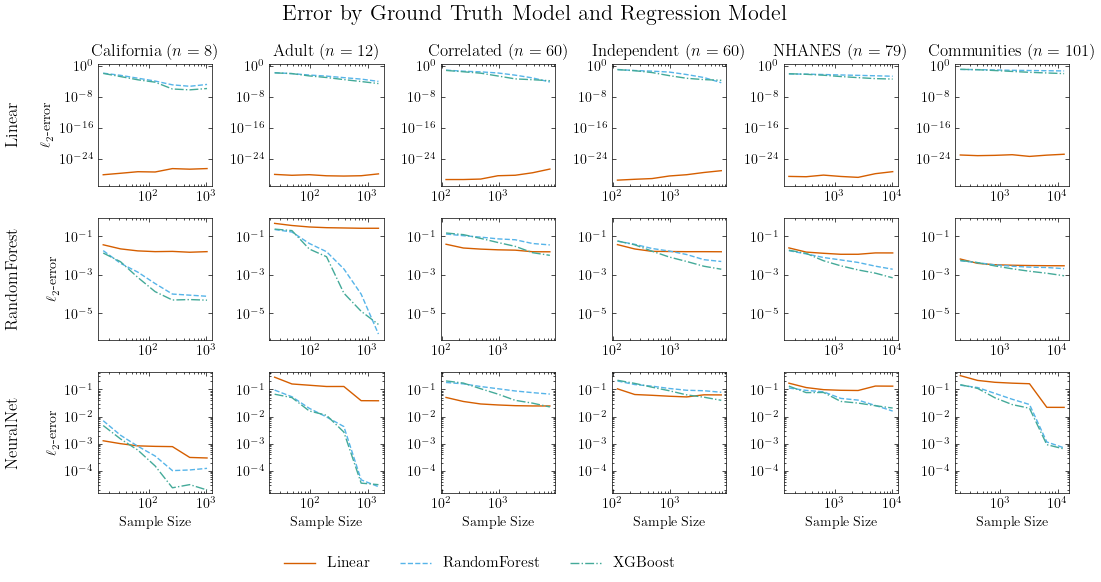

In [46]:
# Make a giant plot
# The columns are the datasets
# The rows are the ground_truth_class
# Each subplot is a line plot of the error for reg_model_class and the x axis is the number of samples

fig, axs = plt.subplots(3, 6, figsize=(11, 5.5))


all_handles = {}
for i, ground_truth_class in enumerate(['Linear', 'RandomForest', 'NeuralNet']):
    for j, dataset in enumerate(dataset_names):
        fit_errors = load_fit_error(dataset, ground_truth_class)
        for reg_model_class_idx, reg_model_class in enumerate(fit_errors.keys()):
            errors = []
            num_samples = []
            for val in fit_errors[reg_model_class]:
                errors.append(np.median(fit_errors[reg_model_class][val]))
                num_samples += [int(dataset_lookup[dataset]*val)]

            line, = axs[i, j].plot(num_samples, errors, 
                                   label=reg_model_class, 
                                   linestyle=linestyles[reg_model_class_idx], 
                                   color=cb_colors[reg_model_class_idx])

            # Add the line handle to the global collection
            if reg_model_class not in all_handles:
                all_handles[reg_model_class] = line
        axs[i, j].set_yscale('log')
        axs[i, j].set_xscale('log')
        if i == 0:
            axs[i, j].set_title(fr'{dataset} ($n={dataset_lookup[dataset]}$)')
        if j == 0:
            axs[i, j].set_ylabel(fr'$\ell_2$-error')
            axs[i,j].annotate(ground_truth_class,
                xy=(-.75, 0.5),              # Coordinates in axis fraction
                xycoords='axes fraction', # Relative to the axis
                fontsize=12,
                rotation=90,              # Rotate to align with y-axis
                ha='center',              # Centered horizontally
                va='center',              # Centered vertically
                color='black')
        if i == 2:
            axs[i, j].set_xlabel('Sample Size')


fig.suptitle(f'Error by Ground Truth Model and Regression Model', fontsize=16)
# Two layers of legends
fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=len(all_handles), bbox_to_anchor=(0.45,0), fontsize=11)
for i in range(3):
    ylims = [ax.get_ylim() for ax in axs[i, :]]

    shared_ylim = (min(y[0] for y in ylims), max(y[1] for y in ylims))

    for ax in axs[i, :]:
        ax.set_ylim(shared_ylim)

plt.tight_layout()
plt.show()